In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
df = pd.read_csv('/content/Mall_Customers.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [5]:
#dataset information
df.info()

#statistical summary
display(df.describe())

#Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Duplicate rows: 0


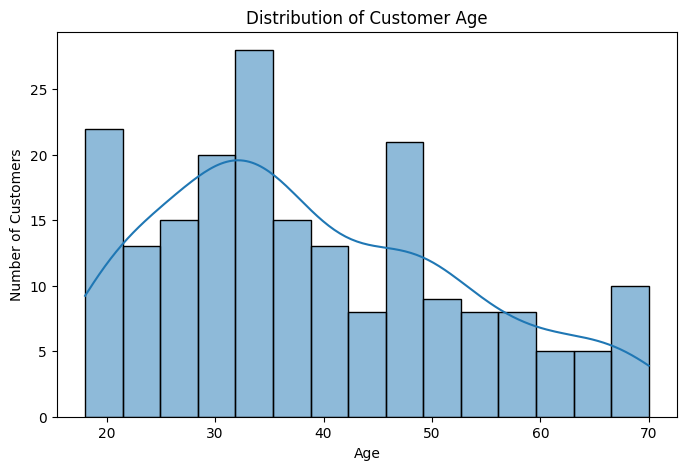

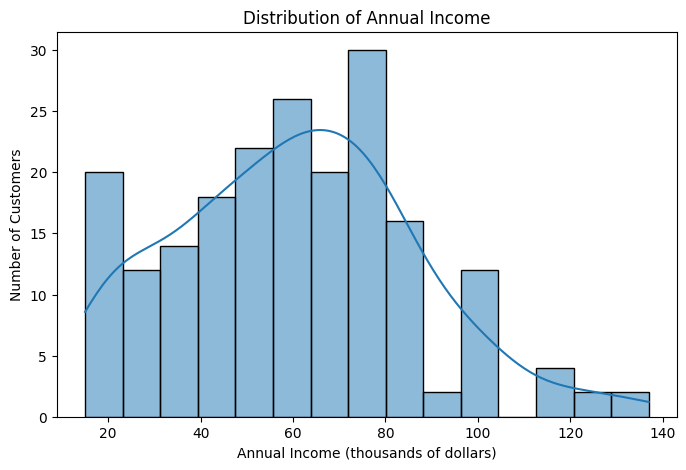

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=15, kde=True)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Annual Income (k$)', bins=15, kde=True)
plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Number of Customers')
plt.show()


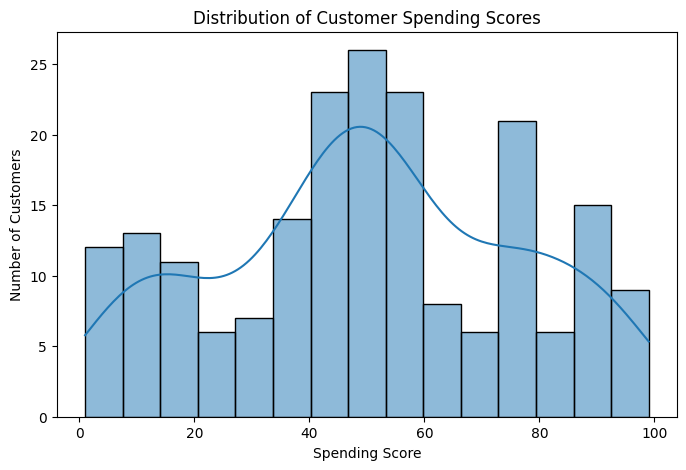

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Spending Score (1-100)', bins=15, kde=True)
plt.title('Distribution of Customer Spending Scores')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')
plt.show()


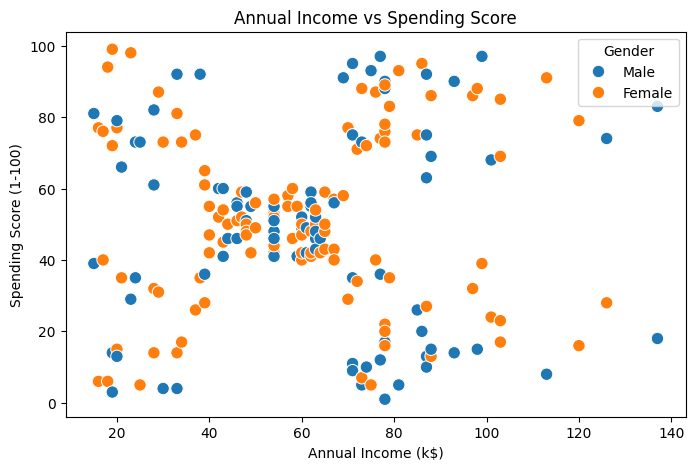

In [13]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=80
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


In [15]:
#the features for customer segmentation
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

#first 5 rows
display(X.head())

print("Selected features:", X.columns.tolist())


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaling completed!")
print("Scaled data shape:", X_scaled.shape)


Data scaling completed!
Scaled data shape: (200, 2)


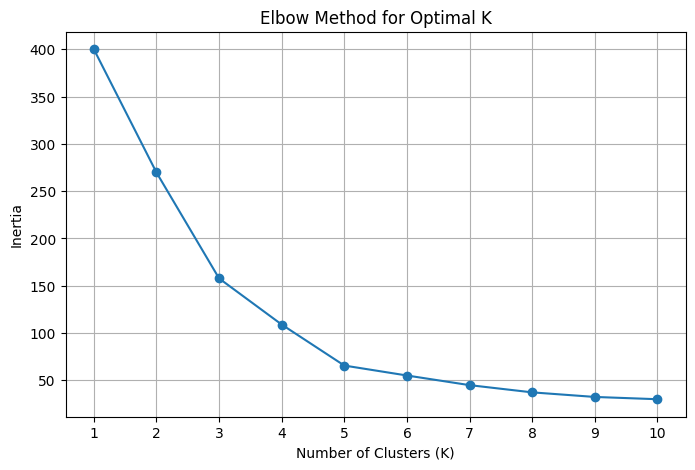

In [19]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [21]:
from sklearn.cluster import KMeans

# Choose the number of clusters
k = 5

# Create and train the model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Assign a cluster to every customer
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")
print("\nCustomers in each cluster:")
print(df['Cluster'].value_counts().sort_index())


K-Means model trained successfully!

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


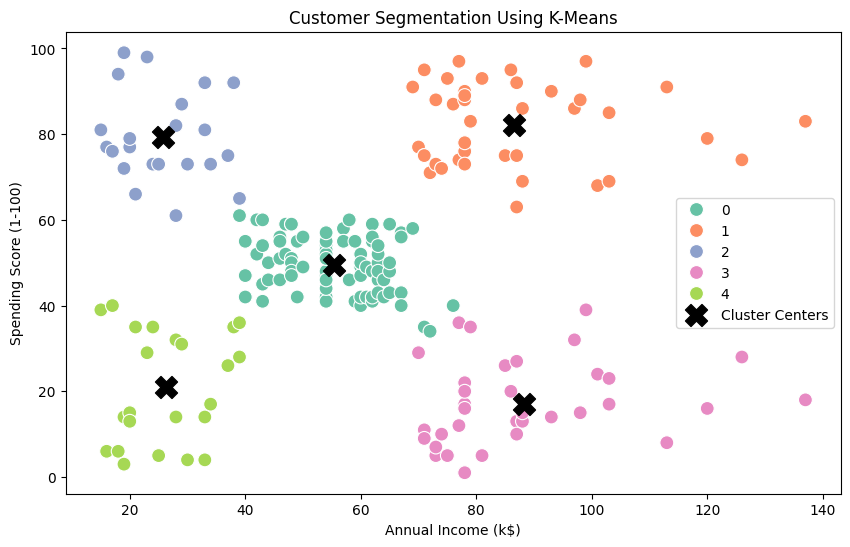

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set2',
    s=100
)
#cluster centers in the original units
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Cluster Centers'
)
plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()


In [25]:
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending=('Spending Score (1-100)', 'mean')
).round(2)
display(cluster_summary)


,Customer_Count,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [27]:
from sklearn.metrics import silhouette_score
score = silhouette_score(X_scaled, df['Cluster'])
print("Silhouette Score:", round(score, 3))
if score > 0.5:
    print("The clusters are reasonably well separated.")
elif score > 0.25:
    print("The clusters show some useful structure.")
else:
    print("The clusters may overlap; try comparing different K values.")

Silhouette Score: 0.555
The clusters are reasonably well separated.


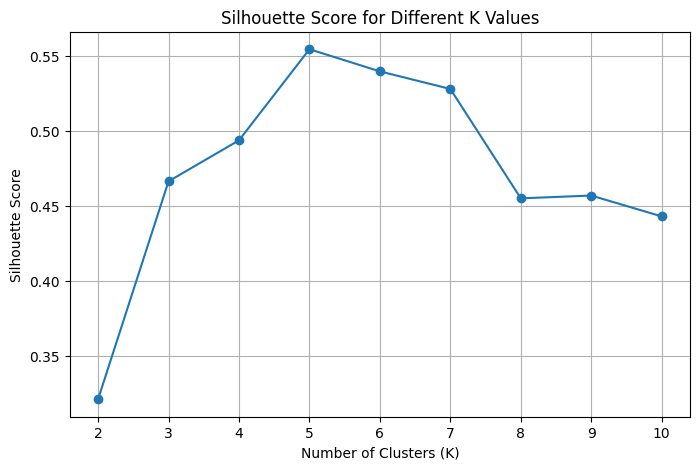

Best K by silhouette score: 5


In [29]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()
best_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]
print("Best K by silhouette score:", best_k)


In [32]:
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
df['Cluster'] = final_kmeans.fit_predict(X_scaled)
# Save the results
df.to_csv('customer_segmentation_results.csv', index=False)
print("Final model trained!")
print("Chosen number of clusters:", best_k)
print("Results saved successfully!")

Final model trained!
Chosen number of clusters: 5
Results saved successfully!


In [33]:
from google.colab import files
files.download('customer_segmentation_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>